<a href="https://colab.research.google.com/github/mjk022/portfolio/blob/main/%EC%A7%80%ED%95%98%EC%B2%A0%EC%97%AD_%EC%9E%90%EC%B9%98%EA%B5%AC%EB%B3%84_%EC%8A%B9%ED%95%98%EC%B0%A8%EC%9D%B8%EC%9B%90.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree       
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 24 not upgraded.
Need to get 9,599 kB of archives.
After this operation, 29.6 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu focal/universe amd64 fonts-nanum all 20180306-3 [9,599 kB]
Fetched 9,599 kB in 1s (14.1 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 76, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122352 files and dir

## 데이터셋

In [ ]:
!pip install teddynote

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 MB 10.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 365.7/365.7 kB 28.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.3/212.3 kB 21.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 9.0 MB/s eta 0:00:00


In [ ]:
from teddynote import dataset

dataset.download('지하철승하차인원')

======= 다운로드 시작 =======

data/지하철_승하차인원.csv


  0%|          | 0.00/31.1k [00:00<?, ?B/s]


======= 다운로드 완료 =======


- [서울교통공사_월별 승하차인원](https://www.data.go.kr/data/15044249/fileData.do)
- [지하철역 주소 정보](http://data.seoul.go.kr/dataList/OA-12035/S/1/datasetView.do)

## 모듈 import & 파일 로드

In [ ]:
import os
import pandas as pd
import numpy as np
import requests
import json
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'NanumGothic'

DATA = 'data'

In [ ]:
# 파일 로드
file1 = os.path.join(DATA, '지하철_승하차인원.csv')
df = pd.read_csv(file1, encoding='euc-kr')
df

,호선,역번호,역명,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
0,1호선,150,서울역(1),3364130,3026680,3446064,3473124,3563150,3302692,3402309,3384029,3205334,3589014,3496294,3543766
1,1호선,151,시청(1),1562110,1275441,1581722,1635208,1666756,1527076,1586068,1592866,1463466,1875878,1691849,1744402
2,1호선,152,종각,2740119,2276059,2650404,2634617,2704398,2458042,2716809,2625393,2354321,2789296,2629753,2875434
3,1호선,153,종로3가(1),2143877,1823175,2106819,2039389,2154261,1989308,2092865,1987469,1843767,2129128,1995373,2133123
4,1호선,154,종로5가,1701378,1452300,1733436,1703251,1749096,1583541,1617625,1571120,1493315,1754767,1673923,1748656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,9호선,4134,송파나루,126242,112765,138597,146349,149438,138761,154548,153004,139389,156361,159925,173431
284,9호선,4135,한성백제,71767,61579,75888,82032,96069,81802,86838,86604,91050,101864,98105,97581
285,9호선,4136,올림픽공원(9),200886,167697,238828,244474,283858,282596,292005,284730,244540,291573,292314,313639
286,9호선,4137,둔촌오륜,29747,27600,38496,39962,40463,39044,40986,38286,40227,43596,44182,43115


## 역명에 대한 클린징

In [ ]:
import re

# Regular Expression 적용하여 ()괄호를 제거 후 추출
pattern_string = r'.+(?=\()'
pattern = re.compile(pattern_string)

In [ ]:
pattern.match('올림픽공원(9)').group().strip()   # 괄호 안에 있는 것에 대해 문자열 첨부터 끝까지 적용하고 공백 지워줘라.

'올림픽공원'

In [ ]:
def clean_station(x):
    # 코드입력
    location = pattern.match(x)
    if location:
        loc = location.group().strip()
    else:
        loc = x
    return loc

In [ ]:
# 코드입력
df['역명_clean'] = df['역명'].apply(clean_station)
df[['역명_clean', '역명']].head(10)

,역명_clean,역명
0,서울역,서울역(1)
1,시청,시청(1)
2,종각,종각
3,종로3가,종로3가(1)
4,종로5가,종로5가
5,동대문,동대문(1)
6,신설동,신설동(1)
7,제기동,제기동
8,청량리,청량리
9,동묘앞,동묘앞(1)


`역명` 컬럼을 제거한 뒤, `역명_clean`컬럼을 `역명`으로 변환합니다.

In [ ]:
# 코드입력
df = df.drop('역명', axis=1)
df = df.rename({'역명_clean':'역명'}, axis=1)
df.head()

,호선,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역명
0,1호선,150,3364130,3026680,3446064,3473124,3563150,3302692,3402309,3384029,3205334,3589014,3496294,3543766,서울역
1,1호선,151,1562110,1275441,1581722,1635208,1666756,1527076,1586068,1592866,1463466,1875878,1691849,1744402,시청
2,1호선,152,2740119,2276059,2650404,2634617,2704398,2458042,2716809,2625393,2354321,2789296,2629753,2875434,종각
3,1호선,153,2143877,1823175,2106819,2039389,2154261,1989308,2092865,1987469,1843767,2129128,1995373,2133123,종로3가
4,1호선,154,1701378,1452300,1733436,1703251,1749096,1583541,1617625,1571120,1493315,1754767,1673923,1748656,종로5가


In [ ]:
df

,호선,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역명
0,1호선,150,3364130,3026680,3446064,3473124,3563150,3302692,3402309,3384029,3205334,3589014,3496294,3543766,서울역
1,1호선,151,1562110,1275441,1581722,1635208,1666756,1527076,1586068,1592866,1463466,1875878,1691849,1744402,시청
2,1호선,152,2740119,2276059,2650404,2634617,2704398,2458042,2716809,2625393,2354321,2789296,2629753,2875434,종각
3,1호선,153,2143877,1823175,2106819,2039389,2154261,1989308,2092865,1987469,1843767,2129128,1995373,2133123,종로3가
4,1호선,154,1701378,1452300,1733436,1703251,1749096,1583541,1617625,1571120,1493315,1754767,1673923,1748656,종로5가
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,9호선,4134,126242,112765,138597,146349,149438,138761,154548,153004,139389,156361,159925,173431,송파나루
284,9호선,4135,71767,61579,75888,82032,96069,81802,86838,86604,91050,101864,98105,97581,한성백제
285,9호선,4136,200886,167697,238828,244474,283858,282596,292005,284730,244540,291573,292314,313639,올림픽공원
286,9호선,4137,29747,27600,38496,39962,40463,39044,40986,38286,40227,43596,44182,43115,둔촌오륜


## 중복 되는 역에 대한 승하차 인원 합계 환산

In [ ]:
df.loc[df['역명'] == '서울역']

,호선,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역명
0,1호선,150,3364130,3026680,3446064,3473124,3563150,3302692,3402309,3384029,3205334,3589014,3496294,3543766,서울역
110,4호선,426,1105093,973842,1167990,1164404,1174031,1091847,1138933,1121257,1056526,1201541,1181427,1204728,서울역


In [ ]:
df.loc[df['역명'] == '고속터미널']

,호선,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역명
79,3호선,329,3650330,3443565,3763343,3549653,3881177,3578839,3659723,3830191,3512161,3719899,3732376,3933493,고속터미널
232,7호선,2736,1200218,1091379,1203247,1187192,1245421,1153031,1185762,1190917,1143816,1258013,1231791,1236209,고속터미널


In [ ]:
#df_역명1 = df.groupby('역명').count()
#df_역명1

,호선,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역명_clean
역명,,,,,,,,,,,,,,,
가락시장(3),1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
가락시장(8),1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
가산디지털단지(7),1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
강남,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
강남구청,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
홍제,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
화곡,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
화랑대,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [ ]:
df_역명 = df.groupby('역명').sum()
df_역명

<ipython-input-14-2aa0a1b006f3>:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_역명 = df.groupby('역명').sum()


,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
역명,,,,,,,,,,,,,
가락시장(3),340,620672,511518,614525,627073,628292,579121,606669,570862,559858,624311,622611,644011
가락시장(8),2818,551346,450430,538633,539310,533333,493338,517594,485677,483584,539011,548024,577474
가산디지털단지(7),2748,2558564,2083546,2442252,2520173,2507799,2262116,2558788,2300971,2218934,2459146,2467699,2430534
강남,222,6731617,5537751,6234948,6070160,6247693,5876947,6809521,6363167,5458954,6073476,6027683,6361642
강남구청,2732,980057,802269,977457,995296,1008723,928293,997659,931419,886769,1007349,1005622,998240
...,...,...,...,...,...,...,...,...,...,...,...,...,...
홍제,314,1131352,977157,1235738,1241081,1272282,1143038,1154822,1097604,1108654,1233937,1193338,1177045
화곡,2518,1762766,1510610,1826195,1854362,1897859,1737139,1822525,1717743,1656990,1839997,1791497,1828432
화랑대,2647,660606,560735,748303,757517,792196,689357,694126,651611,687711,770130,748711,718661


In [ ]:
df_역명.index

Index(['가락시장(3)', '가락시장(8)', '가산디지털단지(7)', '강남', '강남구청', '강동', '강동구청', '강변',
       '개롱', '개화산',
       ...
       '합정(2)', '합정(6)', '행당', '혜화', '홍대입구', '홍제', '화곡', '화랑대', '회현', '효창공원앞'],
      dtype='object', name='역명', length=288)

In [ ]:
df_역명_index=df_역명.reset_index()

df_역명_index.index

RangeIndex(start=0, stop=288, step=1)

In [ ]:
df_역명

,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
역명,,,,,,,,,,,,,
가락시장(3),340,620672,511518,614525,627073,628292,579121,606669,570862,559858,624311,622611,644011
가락시장(8),2818,551346,450430,538633,539310,533333,493338,517594,485677,483584,539011,548024,577474
가산디지털단지(7),2748,2558564,2083546,2442252,2520173,2507799,2262116,2558788,2300971,2218934,2459146,2467699,2430534
강남,222,6731617,5537751,6234948,6070160,6247693,5876947,6809521,6363167,5458954,6073476,6027683,6361642
강남구청,2732,980057,802269,977457,995296,1008723,928293,997659,931419,886769,1007349,1005622,998240
...,...,...,...,...,...,...,...,...,...,...,...,...,...
홍제,314,1131352,977157,1235738,1241081,1272282,1143038,1154822,1097604,1108654,1233937,1193338,1177045
화곡,2518,1762766,1510610,1826195,1854362,1897859,1737139,1822525,1717743,1656990,1839997,1791497,1828432
화랑대,2647,660606,560735,748303,757517,792196,689357,694126,651611,687711,770130,748711,718661


`역명`을 기준으로 승하차인원에 대한 합계를 구합니다.

In [ ]:
# 코드입력
df_total = df.groupby('역명').sum().reset_index().drop('역번호', axis=1)
df_total

<ipython-input-21-c13cdf9964b1>:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_total = df.groupby('역명').sum().reset_index().drop('역번호', axis=1)


,역명,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
0,가락시장(3),620672,511518,614525,627073,628292,579121,606669,570862,559858,624311,622611,644011
1,가락시장(8),551346,450430,538633,539310,533333,493338,517594,485677,483584,539011,548024,577474
2,가산디지털단지(7),2558564,2083546,2442252,2520173,2507799,2262116,2558788,2300971,2218934,2459146,2467699,2430534
3,강남,6731617,5537751,6234948,6070160,6247693,5876947,6809521,6363167,5458954,6073476,6027683,6361642
4,강남구청,980057,802269,977457,995296,1008723,928293,997659,931419,886769,1007349,1005622,998240
...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,홍제,1131352,977157,1235738,1241081,1272282,1143038,1154822,1097604,1108654,1233937,1193338,1177045
284,화곡,1762766,1510610,1826195,1854362,1897859,1737139,1822525,1717743,1656990,1839997,1791497,1828432
285,화랑대,660606,560735,748303,757517,792196,689357,694126,651611,687711,770130,748711,718661
286,회현,1864182,1574625,2027233,2050713,2096872,1909038,1950431,1825184,1719782,2062291,1943588,1952633


**역번호**도 합계가 구해졌기 때문에, 역번호를 이전 데이터프레임으로부터 병합합니다.

In [ ]:
df_merged = pd.merge(df_total, df.drop_duplicates('역명', keep='first')[['역명', '역번호']], how='left')
df_merged

,역명,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역번호
0,가락시장(3),620672,511518,614525,627073,628292,579121,606669,570862,559858,624311,622611,644011,340
1,가락시장(8),551346,450430,538633,539310,533333,493338,517594,485677,483584,539011,548024,577474,2818
2,가산디지털단지(7),2558564,2083546,2442252,2520173,2507799,2262116,2558788,2300971,2218934,2459146,2467699,2430534,2748
3,강남,6731617,5537751,6234948,6070160,6247693,5876947,6809521,6363167,5458954,6073476,6027683,6361642,222
4,강남구청,980057,802269,977457,995296,1008723,928293,997659,931419,886769,1007349,1005622,998240,2732
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,홍제,1131352,977157,1235738,1241081,1272282,1143038,1154822,1097604,1108654,1233937,1193338,1177045,314
284,화곡,1762766,1510610,1826195,1854362,1897859,1737139,1822525,1717743,1656990,1839997,1791497,1828432,2518
285,화랑대,660606,560735,748303,757517,792196,689357,694126,651611,687711,770130,748711,718661,2647
286,회현,1864182,1574625,2027233,2050713,2096872,1909038,1950431,1825184,1719782,2062291,1943588,1952633,425


**고속터미널** 역에 대한 합계치 비교

In [ ]:
df.loc[df['역명'] == '고속터미널']

,호선,역번호,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역명
79,3호선,329,3650330,3443565,3763343,3549653,3881177,3578839,3659723,3830191,3512161,3719899,3732376,3933493,고속터미널
232,7호선,2736,1200218,1091379,1203247,1187192,1245421,1153031,1185762,1190917,1143816,1258013,1231791,1236209,고속터미널


In [ ]:
df_merged.loc[df_merged['역명'] == '고속터미널']

,역명,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역번호
15,고속터미널,4850548,4534944,4966590,4736845,5126598,4731870,4845485,5021108,4655977,4977912,4964167,5169702,329


## `seoul_station_geocode.csv` 파일 로드

In [ ]:
address = pd.read_csv('https://raw.githubusercontent.com/teddylee777/dip/main/assets/seoul_station_geocode.csv')
address.head()

,호선,역명,lat,lng,주소,역번호
0,1,서울역,37.564119,126.976808,서울특별시 중구 세종대로 지하 2,150
1,1,시청,37.565704,126.976862,서울특별시 중구 세종대로 지하 101,151
2,1,종각,37.570169,126.983099,서울특별시 종로구 종로 지하 55,152
3,1,종로3가,37.570371,126.991005,서울특별시 종로구 종로 지하 129,153
4,1,종로5가,37.559785,126.970986,서울특별시 종로구 종로 지하 216,154


In [ ]:
# 코드입력
merged_data = pd.merge(df_merged, address[['주소', '역명', 'lat', 'lng']], on='역명', how='left')
merged_data.head()

,역명,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역번호,주소,lat,lng
0,가락시장(3),620672,511518,614525,627073,628292,579121,606669,570862,559858,624311,622611,644011,340,NaN,NaN,NaN
1,가락시장(8),551346,450430,538633,539310,533333,493338,517594,485677,483584,539011,548024,577474,2818,NaN,NaN,NaN
2,가산디지털단지(7),2558564,2083546,2442252,2520173,2507799,2262116,2558788,2300971,2218934,2459146,2467699,2430534,2748,NaN,NaN,NaN
3,강남,6731617,5537751,6234948,6070160,6247693,5876947,6809521,6363167,5458954,6073476,6027683,6361642,222,서울특별시 강남구 강남대로 지하 396,37.497786,127.027777
4,강남구청,980057,802269,977457,995296,1008723,928293,997659,931419,886769,1007349,1005622,998240,2732,서울특별시 강남구 학동로 지하346,37.517133,127.041299


In [ ]:
df_merged.shape, merged_data.shape

((288, 14), (288, 17))

병합된 데이터셋에 대한 결측치 확인

In [ ]:
merged_data.isnull().sum()

역명      0
1월      0
2월      0
3월      0
4월      0
5월      0
6월      0
7월      0
8월      0
9월      0
10월     0
11월     0
12월     0
역번호     0
주소     88
lat    88
lng    88
dtype: int64

## 주소 데이터 분할

In [ ]:
# 코드입력
merged_data['주소'].str.split()

0                                NaN
1                                NaN
2                                NaN
3        [서울특별시, 강남구, 강남대로, 지하, 396]
4           [서울특별시, 강남구, 학동로, 지하346]
                   ...              
283    [서울특별시, 서대문구, 통일로, 지하, 440-1]
284         [서울특별시, 강서구, 화곡로, 지하168]
285         [서울특별시, 노원구, 화랑로, 지하510]
286         [서울특별시, 중구, 퇴계로, 지하, 54]
287         [서울특별시, 용산구, 백범로, 지하287]
Name: 주소, Length: 288, dtype: object

**구**만 추출하기

In [ ]:
# 코드입력
merged_data['주소'].str.split().str[1]

0       송파구
1       금천구
2       강남구
3       강남구
4       강동구
       ... 
246    서대문구
247     강서구
248     노원구
249      중구
250     용산구
Name: 주소, Length: 251, dtype: object

In [ ]:
# 코드입력
merged_data['구'] = merged_data['주소'].str.split().str[1]
merged_data['구']

0       NaN
1       NaN
2       NaN
3       강남구
4       강남구
       ... 
283    서대문구
284     강서구
285     노원구
286      중구
287     용산구
Name: 구, Length: 288, dtype: object

In [ ]:
merged_data.head()

,역명,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역번호,주소,lat,lng,구
0,가락시장(3),620672,511518,614525,627073,628292,579121,606669,570862,559858,624311,622611,644011,340,NaN,NaN,NaN,NaN
1,가락시장(8),551346,450430,538633,539310,533333,493338,517594,485677,483584,539011,548024,577474,2818,NaN,NaN,NaN,NaN
2,가산디지털단지(7),2558564,2083546,2442252,2520173,2507799,2262116,2558788,2300971,2218934,2459146,2467699,2430534,2748,NaN,NaN,NaN,NaN
3,강남,6731617,5537751,6234948,6070160,6247693,5876947,6809521,6363167,5458954,6073476,6027683,6361642,222,서울특별시 강남구 강남대로 지하 396,37.497786,127.027777,강남구
4,강남구청,980057,802269,977457,995296,1008723,928293,997659,931419,886769,1007349,1005622,998240,2732,서울특별시 강남구 학동로 지하346,37.517133,127.041299,강남구


## folium을 활용한 지도 시각화

In [ ]:
import folium

# 위도
latitude = 37.559819
# 경도
longitude = 126.963895

m = folium.Map(location=[latitude, longitude],
               zoom_start=17,
               width=750,
               height=500
              )
m

타일을 `cartodbpositron`으로 변경합니다.

In [ ]:
m = folium.Map(
    location=[37.559819, 126.963895],
    zoom_start=11,
    tiles='cartodbpositron'
)
m

## 서울 행정구역 표기 및 시각화에 boundary 적용

In [ ]:
# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)
seoul_geo

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'properties': {'code': '11250',
    'name': '강동구',
    'name_eng': 'Gangdong-gu',
    'base_year': '2013'},
   'geometry': {'type': 'Polygon',
    'coordinates': [[[127.11519584981606, 37.557533180704915],
      [127.11879551821994, 37.557222485451305],
      [127.12146867175024, 37.55986003393365],
      [127.12435254630417, 37.56144246249796],
      [127.13593925898998, 37.56564793048277],
      [127.14930548011061, 37.56892250303897],
      [127.15511020940411, 37.57093642128295],
      [127.16683184366129, 37.57672487388627],
      [127.17038810813094, 37.576465605301046],
      [127.17607118428914, 37.57678573961056],
      [127.17905504160184, 37.57791388161732],
      [127.17747787800164, 37.57448983055031],
      [127.1781775408844, 37.571481967974336],
      [127.17995281860672, 37.569309661290504],
      [127.18122821955262, 37.56636089217979],
      [127.18169407550688, 37.56286338914073],
      [127.18408792

In [ ]:
merged_data

,역명,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월,역번호,주소,lat,lng,구
0,가락시장(3),620672,511518,614525,627073,628292,579121,606669,570862,559858,624311,622611,644011,340,NaN,NaN,NaN,NaN
1,가락시장(8),551346,450430,538633,539310,533333,493338,517594,485677,483584,539011,548024,577474,2818,NaN,NaN,NaN,NaN
2,가산디지털단지(7),2558564,2083546,2442252,2520173,2507799,2262116,2558788,2300971,2218934,2459146,2467699,2430534,2748,NaN,NaN,NaN,NaN
3,강남,6731617,5537751,6234948,6070160,6247693,5876947,6809521,6363167,5458954,6073476,6027683,6361642,222,서울특별시 강남구 강남대로 지하 396,37.497786,127.027777,강남구
4,강남구청,980057,802269,977457,995296,1008723,928293,997659,931419,886769,1007349,1005622,998240,2732,서울특별시 강남구 학동로 지하346,37.517133,127.041299,강남구
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,홍제,1131352,977157,1235738,1241081,1272282,1143038,1154822,1097604,1108654,1233937,1193338,1177045,314,서울특별시 서대문구 통일로 지하 440-1,37.588802,126.944112,서대문구
284,화곡,1762766,1510610,1826195,1854362,1897859,1737139,1822525,1717743,1656990,1839997,1791497,1828432,2518,서울특별시 강서구 화곡로 지하168,37.573094,126.818151,강서구
285,화랑대,660606,560735,748303,757517,792196,689357,694126,651611,687711,770130,748711,718661,2647,서울특별시 노원구 화랑로 지하510,37.558816,126.927414,노원구
286,회현,1864182,1574625,2027233,2050713,2096872,1909038,1950431,1825184,1719782,2062291,1943588,1952633,425,서울특별시 중구 퇴계로 지하 54,37.560972,126.994597,중구


자치구별 1월의 승하차인원 합계량을 산출합니다.

In [ ]:
# 코드입력
data_1=merged_data.groupby('구')['1월'].sum()

data_1

구
강남구     31986874
강동구      6544672
강북구      5068922
강서구      5490242
고양시        74540
관악구     10851160
광명시      3106352
광진구      7737213
구로구      9213584
노원구      6998245
도봉구      3726162
동대문구     4335220
동작구      6342444
마포구     14949114
부천시      3895473
부평구       896508
서대문구     1862969
서초구      9103236
성남시      2415930
성동구      8042337
성북구      6871698
송파구      8379226
양천구      4549536
영등포구     4426410
용산구      4937754
은평구      5329757
의정부시       96454
종로구     13432458
중구       7995768
중랑구      4228832
Name: 1월, dtype: int64

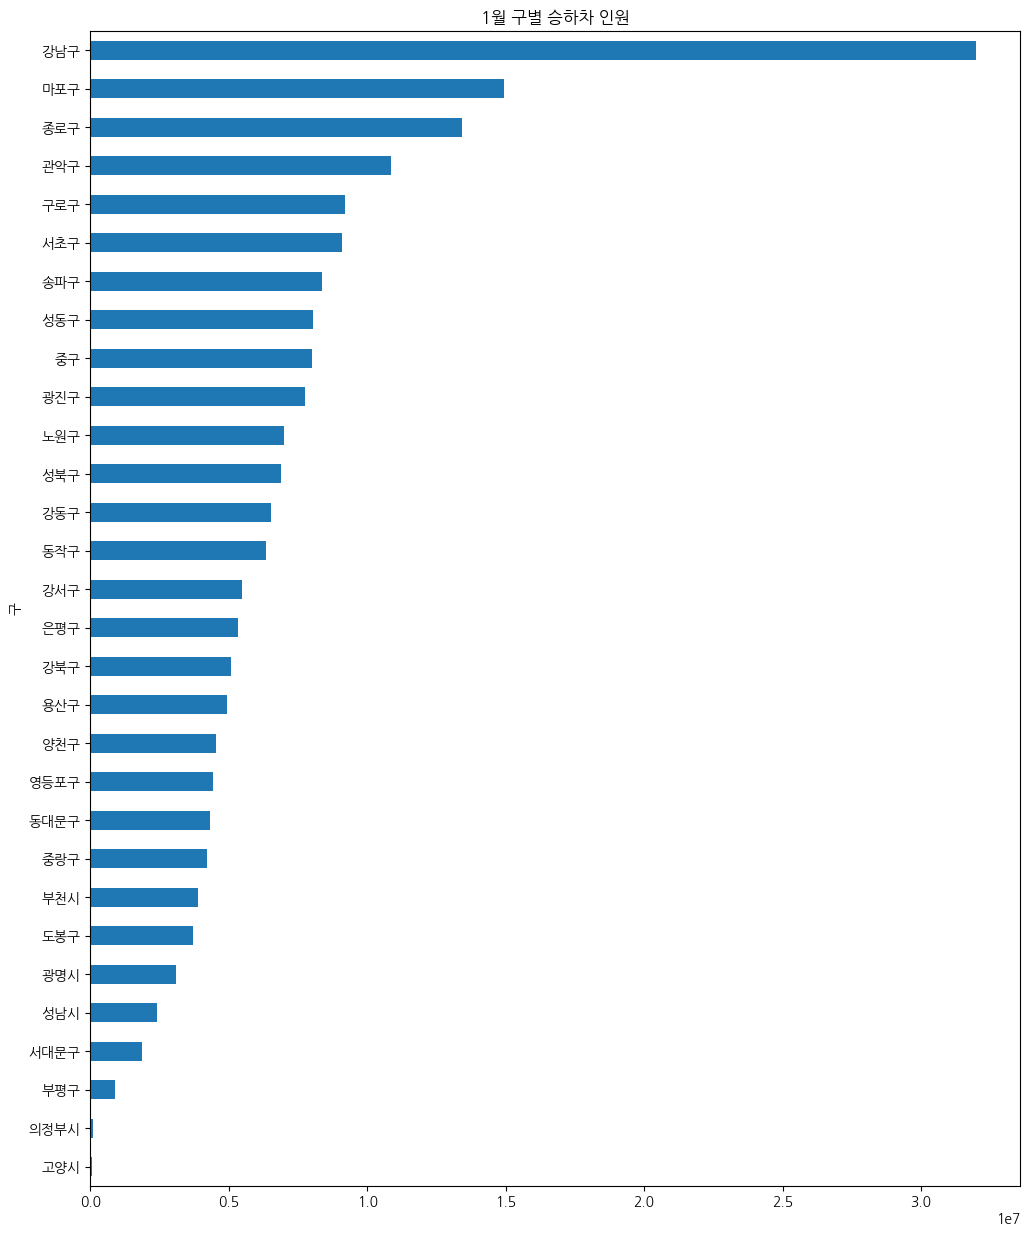

In [ ]:
# 월 설정
N = 1

plt.figure(figsize=(12, 15))
merged_data.groupby('구')[f'{N}월'].sum().sort_values().plot(kind='barh')
plt.title(f'{N}월 구별 승하차 인원')
plt.show()

In [ ]:
m = folium.Map(
    location=[37.559819, 126.963895],
    zoom_start=10,
    tiles='cartodbpositron'
)

folium.GeoJson(
    seoul_geo,
    name='지역구'
).add_to(m)

m.choropleth(geo_data=seoul_geo,
             data=data_1,
             fill_color='YlOrRd', # 색상 변경도 가능하다
             fill_opacity=0.9,
             line_opacity=0.2,
             key_on='properties.name',
             legend_name=f'{N}월 승하차 인원',
            )
m

/usr/local/lib/python3.9/dist-packages/folium/folium.py:465: FutureWarning: The choropleth  method has been deprecated. Instead use the new Choropleth class, which has the same arguments. See the example notebook 'GeoJSON_and_choropleth' for how to do this.
  warnings.warn(
